# Peform the VM2R.

-> Is a statical metric used to quantify the relative variability of the signal with respect
to its typical level (median) power level. It is used to RFI detection beacuse it reduces 
sensitivity to extreme outliers compared to mean.

In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib import cm, colors as mcolors
import matplotlib.ticker as mticker


# import imageio # to collect frames and write them into an animated file.
import os
# from PIL import Image
# import io

import scienceplots
plt.style.use(['science', 'no-latex'])

from typing import Optional

from pybaselines import Baseline, utils 
from scipy.signal import find_peaks, detrend
from scipy.stats import skew, kurtosis, gaussian_kde
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

#from concurrent.futures import ProcessPoolExecutor


# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [2]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# # Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = False

In [3]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e9
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [4]:
datasets.keys()

dict_keys(['scan/000/P1_ND0', 'scan/000/P1_ND1', 'scan/001/P0_ND0', 'scan/001/P0_ND1', 'scan/001/P1_ND0', 'scan/001/P1_ND1'])

In [5]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 163MB
Dimensions:           (time: 634, frequency: 63877, integration_time: 634,
                       ra: 634, dec: 634, elevation: 634, azimuth: 634)
Coordinates:
  * time              (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09
  * frequency         (frequency) float64 511kB 1.793 1.793 ... 3.498 3.498
  * integration_time  (integration_time) float64 5kB 0.1158 0.1129 ... 0.1159
  * ra                (ra) float64 5kB 82.06 82.06 82.07 ... 85.21 85.22 85.22
  * dec               (dec) float64 5kB 22.68 22.68 22.68 ... 21.3 21.3 21.29
  * elevation         (elevation) float64 5kB 30.51 30.5 30.51 ... 30.51 30.51
  * azimuth           (azimuth) float64 5kB 29.42 29.42 29.42 ... 32.78 32.79
Data variables:
    spectrum          (time, frequency) float32 162MB 1.883e+11 ... 4.159e+09

In [6]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_ghz = data['frequency'].values 
time = data['time'].values
elevation = data['elevation'].values
azimuth = data['azimuth'].values





# Spectrum to dB
spectrum_db = 10*np.log10(spectrum**2)
mean_spectrum_db = np.mean(spectrum_db, axis=0)


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


In [7]:
mean_spectrum_db.shape

(63877,)

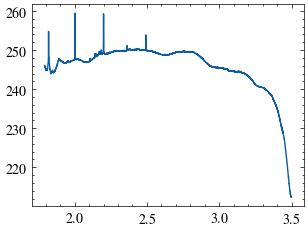

In [8]:
plt.plot(frequency_ghz, mean_spectrum_db)

# Import the functions

In [9]:

# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline




# quantify the outliers
def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels,
        
            
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} GHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} GHz")
        print(f"  End Frequency  : {end_freq:.4f} GHz")
        print(f"  Bandwidth      : {bandwidth:.4f} GHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(10,6))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label='Threshold = 0.05 dB')
            plt.xlabel("Frequency [GHz]", fontsize=16)
            plt.ylabel("Detrended Power [log(dB)]", fontsize=16)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} GHz")
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.legend(fontsize=12)
            # plt.show()



            plt.savefig(
            f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.png",
            dpi=300,
            bbox_inches="tight"
        )

            plt.savefig(
                f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.pdf",
                dpi=300,
                bbox_inches="tight"
            )



    return results_outliers


# RFI mask

def build_rfi_mask(freq, results_outliers):
    """
    Create boolean mask for RFI contaminated channels.

    Returns:
        mask : True = flagged (RFI)
    """
    mask = np.zeros(len(freq), dtype=bool)

    for res in results_outliers:
        start = res["start_freq"]
        end = res["end_freq"]

        # Flag all frequencies inside range
        mask |= (freq >= start) & (freq <= end)

    return mask


# Compute VM^2R for single-dish data
def variance_to_median_square_ratio_single_dish(
    obj,
    time_dim: str = "time",
    freq_dim: str = "freq",
    pol_dim: str | None = None,
    eps: float = 1e-12,
) -> xr.Dataset:
    """
    Compute the variance-to-median-square ratio (VM^2R) over time for a
    single-dish dataset.

    Parameters
    ----------
    obj : xr.DataArray or xr.Dataset
        Input dynamic spectrum. If a Dataset is provided, the first data variable
        is used. Expected dimensions include time and frequency, and optionally
        polarization.
    time_dim : str, optional
        Name of the time dimension. Default is "time".
    freq_dim : str, optional
        Name of the frequency dimension. Default is "freq".
    pol_dim : str or None, optional
        Name of the polarization/feed dimension, if present. If None, the
        function assumes no extra per-feed/pol dimension. Default is None.
    eps : float, optional
        Small positive floor used to avoid division by zero. Default is 1e-12.

    Returns
    -------
    xr.Dataset
        Contains:
        - median: time-median per (freq[, pol])
        - variance: time-variance per (freq[, pol])
        - vm2r: variance / median^2 per (freq[, pol])
        - vm2r_by_freq: median VM^2R over polarization/feed (if pol_dim exists),
                        otherwise same as vm2r
        - vm2r_by_pol: median VM^2R over frequency (if pol_dim exists)
        - vm2r_global: global median VM^2R

    Notes
    -----
    VM^2R = Var(X) / Median(X)^2

    For single-dish total-power data this is useful for flagging non-stationary,
    bursty, or RFI-like behaviour in the time-frequency plane.
    """
    # Handle Dataset vs DataArray
    if isinstance(obj, xr.Dataset):
        var_name = list(obj.data_vars)[0]
        data_da = obj[var_name]
    else:
        data_da = obj

    # Check required dims
    required_dims = {time_dim, freq_dim}
    missing = required_dims - set(data_da.dims)
    if missing:
        raise ValueError(f"Input is missing required dimensions: {missing}")

    if pol_dim is not None and pol_dim not in data_da.dims:
        raise ValueError(f"pol_dim='{pol_dim}' not found in input dimensions {data_da.dims}")

    # Compute time statistics
    x = data_da.chunk({time_dim: -1})
    time_median = x.median(dim=time_dim, skipna=True).rename("median")
    time_variance = x.var(dim=time_dim, skipna=True).rename("variance")

    # VM^2R
    denom = time_median**2
    vm2r = (time_variance / denom).rename("vm2r")
    vm2r = vm2r.where(np.abs(time_median) > eps)

    out = {
        "median": time_median,
        "variance": time_variance,
        "vm2r": vm2r,
    }

    # 1D summaries
    if pol_dim is not None:
        vm2r_by_pol = (
            vm2r.chunk({freq_dim: -1})
            .median(dim=freq_dim, skipna=True)
            .rename("vm2r_by_pol")
        )
        vm2r_by_freq = (
            vm2r.chunk({pol_dim: -1})
            .median(dim=pol_dim, skipna=True)
            .rename("vm2r_by_freq")
        )
        out["vm2r_by_pol"] = vm2r_by_pol
        out["vm2r_by_freq"] = vm2r_by_freq
    else:
        out["vm2r_by_freq"] = vm2r.rename("vm2r_by_freq")

    # Global median
    vm2r_global = xr.DataArray(
        np.nanmedian(vm2r.compute().values),
        name="vm2r_global"
    )
    out["vm2r_global"] = vm2r_global

    return xr.Dataset(out)

In [10]:
# Compute VM^2R as a function of time for single-dish data
def variance_to_median_square_ratio_time(
    obj,
    time_dim: str = "time",
    freq_dim: str = "freq",
    pol_dim: str | None = None,
    eps: float = 1e-12,
) -> xr.Dataset:
    """
    Compute the Variance-to-Median-Square Ratio (VM^2R)
    as a function of time.

    VM^2R(t) = Var_f[X(f,t)] / Median_f[X(f,t)]^2

    Parameters
    ----------
    obj : xr.DataArray or xr.Dataset
        Dynamic spectrum containing time-frequency data.
    time_dim : str
        Name of the time dimension.
    freq_dim : str
        Name of the frequency dimension.
    pol_dim : str or None
        Optional polarization/feed dimension.
    eps : float
        Small threshold to avoid division by zero.

    Returns
    -------
    xr.Dataset
        Dataset containing:
        - median(time[, pol])
        - variance(time[, pol])
        - vm2r(time[, pol])
        - vm2r_by_time(time)
        - vm2r_global
    """

    # Handle Dataset vs DataArray
    if isinstance(obj, xr.Dataset):
        var_name = list(obj.data_vars)[0]
        data_da = obj[var_name]
    else:
        data_da = obj

    # Check required dimensions
    required_dims = {time_dim, freq_dim}
    missing = required_dims - set(data_da.dims)

    if missing:
        raise ValueError(f"Missing required dimensions: {missing}")

    if pol_dim is not None and pol_dim not in data_da.dims:
        raise ValueError(
            f"pol_dim='{pol_dim}' not found in dimensions {data_da.dims}"
        )

    # Chunk over frequency for efficient statistics
    x = data_da.chunk({freq_dim: -1})

    # Frequency statistics at each time sample
    freq_median = (
        x.median(dim=freq_dim, skipna=True)
        .rename("median")
    )

    freq_variance = (
        x.var(dim=freq_dim, skipna=True)
        .rename("variance")
    )

    # VM^2R(t)
    denom = freq_median**2

    vm2r = (
        freq_variance / denom
    ).rename("vm2r")

    # Avoid division by zero
    vm2r = vm2r.where(np.abs(freq_median) > eps)

    out = {
        "median": freq_median,
        "variance": freq_variance,
        "vm2r": vm2r,
    }

    # Collapse polarization if present
    if pol_dim is not None:
        vm2r_by_time = (
            vm2r
            .median(dim=pol_dim, skipna=True)
            .rename("vm2r_by_time")
        )
    else:
        vm2r_by_time = vm2r.rename("vm2r_by_time")

    out["vm2r_by_time"] = vm2r_by_time

    # Global statistic
    vm2r_global = xr.DataArray(
        np.nanmedian(vm2r.values),
        name="vm2r_global"
    )

    out["vm2r_global"] = vm2r_global

    return xr.Dataset(out)

Detected peak > 3σ are frequencies (GHz): ['1.8196', '2.0028', '2.1841', '2.1999', '2.3629', '2.4920']


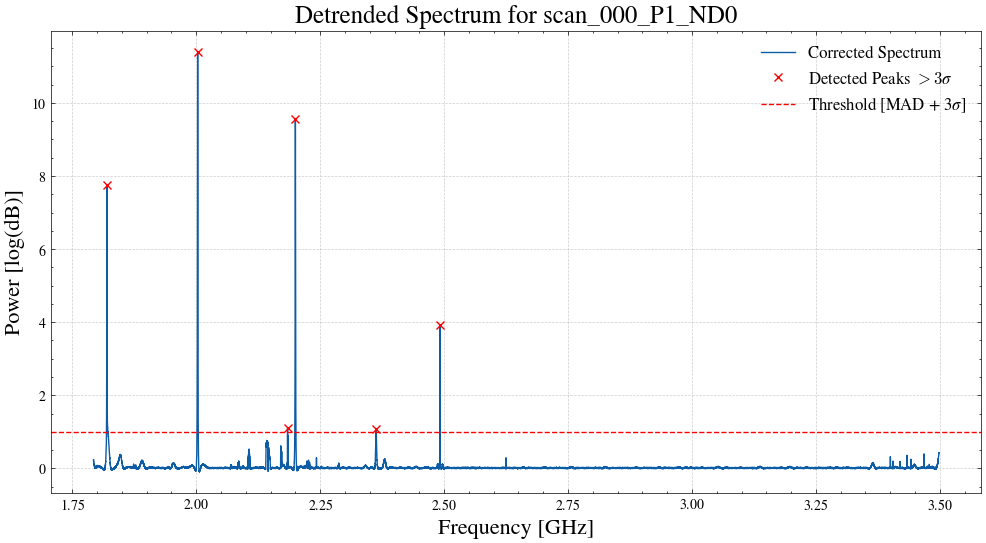

In [11]:
# Detrend the signal
detrended_spectrum = base_correction(frequency_ghz, mean_spectrum_db)

# Find peaks above 1 sigma from the MAD
peaks, propreties = find_peaks(detrended_spectrum, 
                            height=MAD(detrended_spectrum) + 3*np.std(detrended_spectrum),
                            distance=10,
                            prominence=0.5
                            )
plt.figure(figsize=(12,6))
plt.plot(frequency_ghz, detrended_spectrum, label='Corrected Spectrum')
plt.plot(frequency_ghz[peaks],  detrended_spectrum[peaks], 'x', color='red', label='Detected Peaks $>3σ$')
plt.axhline(y=MAD(detrended_spectrum) + 3*np.std(detrended_spectrum), 
                color='red', linestyle='--', label='Threshold [MAD + 3$σ$]')
plt.xlabel("Frequency [GHz]", fontsize=16)
plt.ylabel("Power [log(dB)]", fontsize=16)
plt.title(f"Detrended Spectrum for {scan_name}", fontsize=18)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=12)

  # --- Print detected peak frequencies ---
peak_freqs = [f"{f:.4f}" for f in frequency[peaks]]

print(f"Detected peak > 3σ are frequencies (GHz): {peak_freqs}")


Peak frequencies to analyze: [1.8196, 2.0028, 2.1841, 2.1999, 2.3629, 2.492]

Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 7.6941 dB
  Start Frequency: 1.8163 GHz
  End Frequency  : 1.8271 GHz
  Bandwidth      : 0.0108 GHz
  Corrupted Ch.  : 404 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 11.3763 dB
  Start Frequency: 2.0002 GHz
  End Frequency  : 2.0050 GHz
  Bandwidth      : 0.0048 GHz
  Corrupted Ch.  : 179 channels

Outlier 3:
  Peak Frequency : 2.1841 GHz
  Peak Power     : 0.2541 dB
  Start Frequency: 2.1840 GHz
  End Frequency  : 2.1843 GHz
  Bandwidth      : 0.0002 GHz
  Corrupted Ch.  : 8 channels

Outlier 4:
  Peak Frequency : 2.1999 GHz
  Peak Power     : 9.5290 dB
  Start Frequency: 2.1973 GHz
  End Frequency  : 2.2023 GHz
  Bandwidth      : 0.0049 GHz
  Corrupted Ch.  : 185 channels

Outlier 5:
  Peak Frequency : 2.3629 GHz
  Peak Power     : 1.0645 dB
  Start Frequency: 2.3605 GHz
  End Frequency  : 2.3655 GHz
  Bandwidth      : 0.

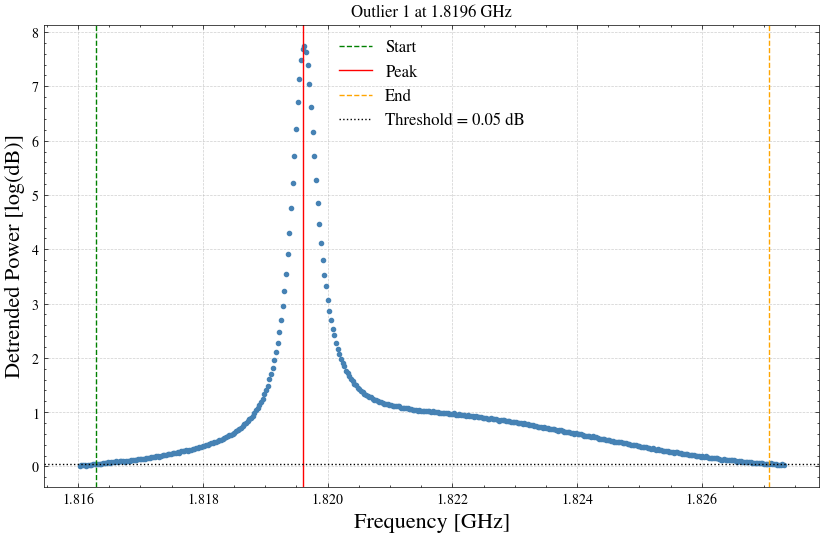

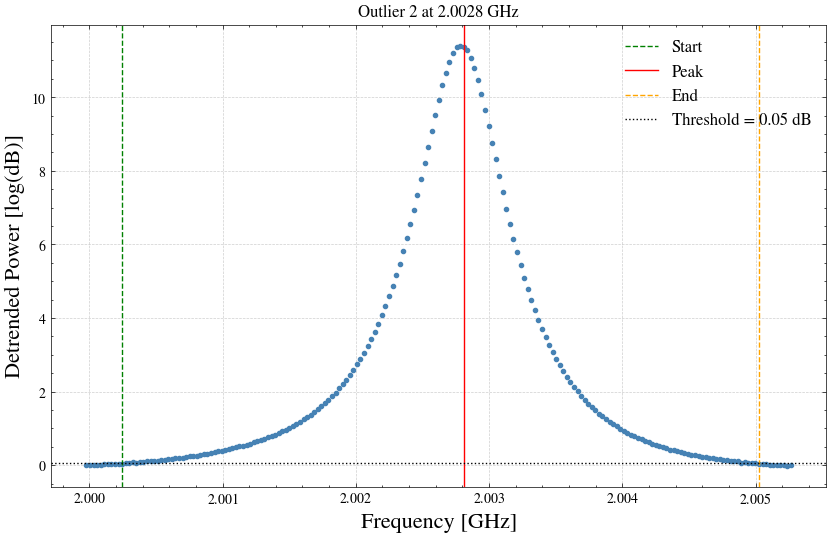

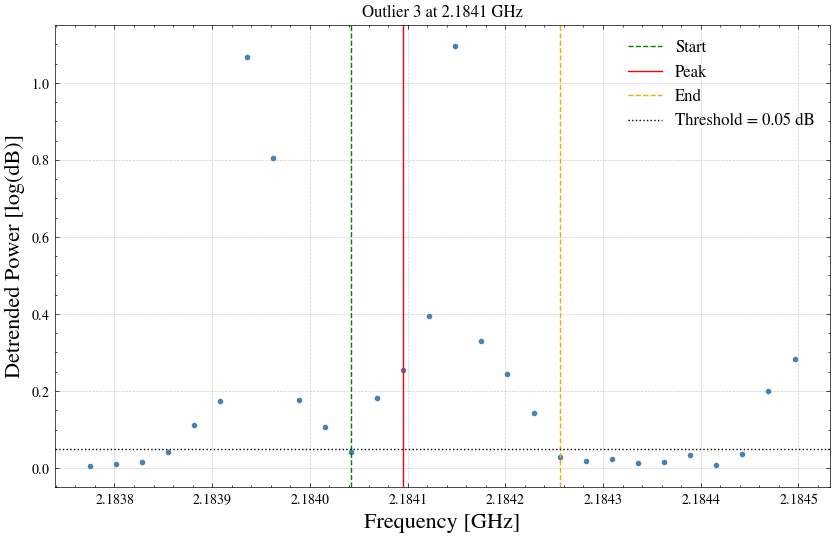

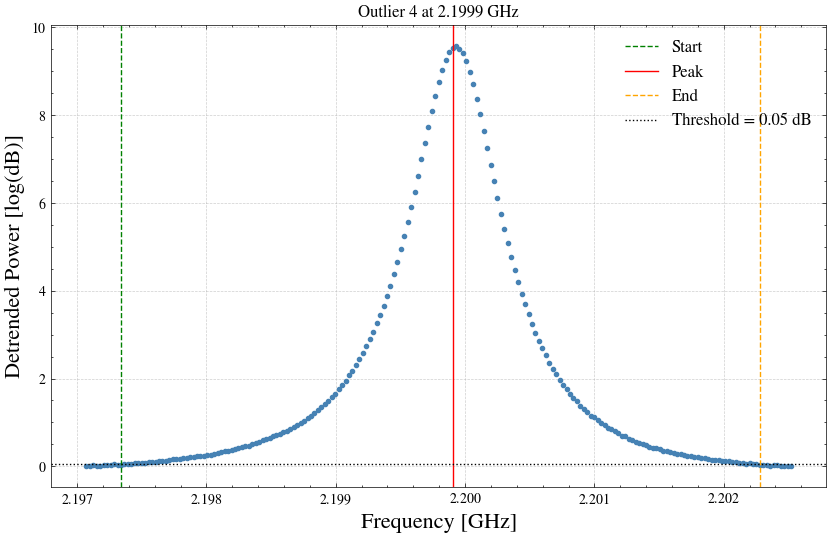

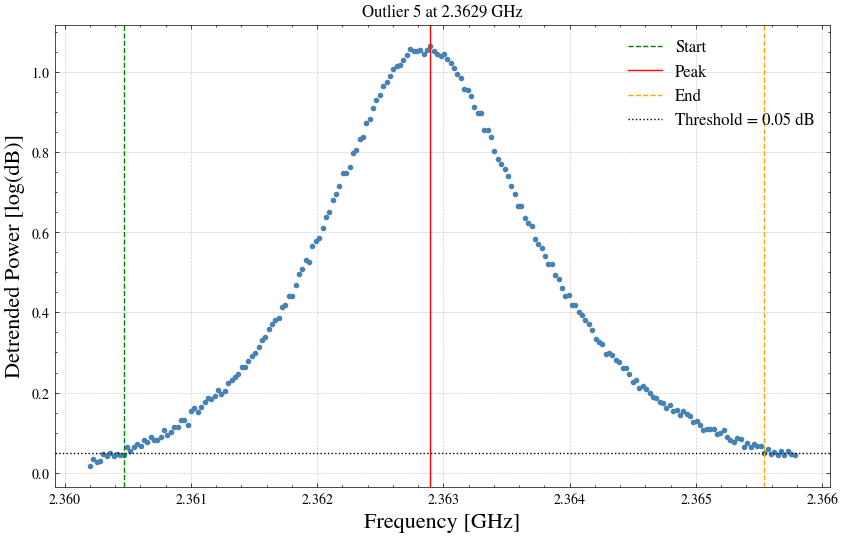

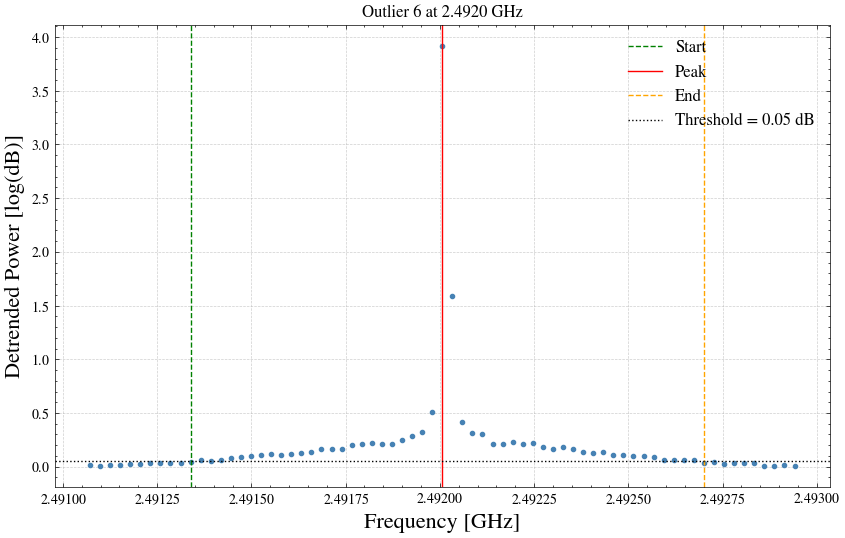

In [12]:
# Analyze each detected outlier
peak_freqs = [float(f) for f in peak_freqs]
print(f'Peak frequencies to analyze: {peak_freqs}')
results_outliers = quantify_all_outliers(frequency, detrended_spectrum, peak_freqs, plot=True)

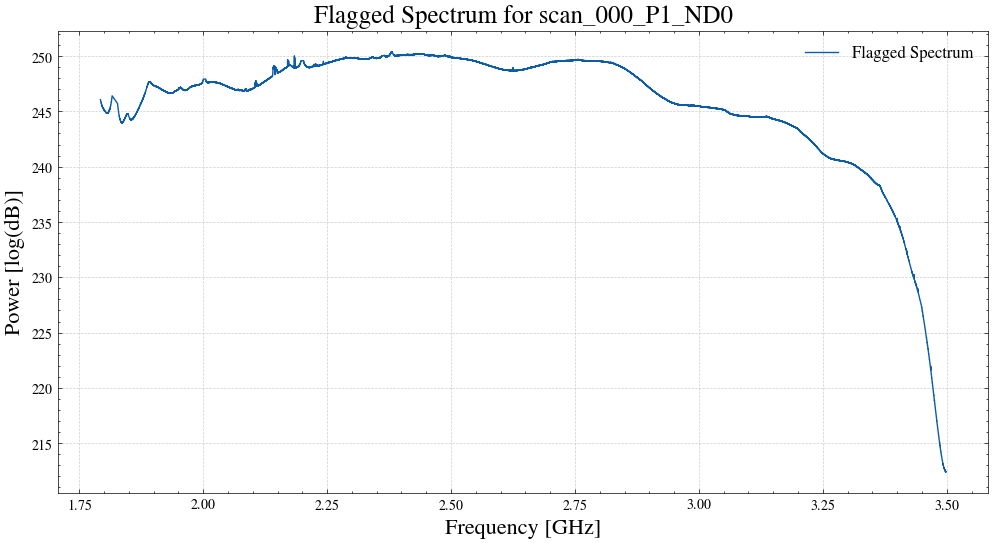

In [13]:

# 1) Build mask (must correspond to THIS time step)
flag = build_rfi_mask(frequency_ghz, results_outliers)


# 3) Apply mask (1D indexing!)
# spectrum_flagged = mean_spectrum_db.copy()
# spectrum_flagged[flag] = np.nan

mask_signal = spectrum_db[:,~flag]
mask_frequency_ghz = frequency_ghz[~flag]
mask_signal_mean = np.mean(mask_signal, axis=0)

mask_signal.shape, mask_frequency_ghz.shape, mask_signal_mean.shape

# # Plot the spectrum with flagged channels
plt.figure(figsize=(12,6))
plt.plot(mask_frequency_ghz, mask_signal_mean, label='Flagged Spectrum')
plt.xlabel("Frequency [GHz]", fontsize=16)
plt.ylabel("Power [log(dB)]", fontsize=16)
plt.title(f"Flagged Spectrum for {scan_name}", fontsize=18)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=12)

Detected peak > 5σ are frequencies (GHz): ['1.8163', '2.1064', '2.1421', '2.1459', '2.1703', '2.1707', '2.1839', '2.1845', '2.1849']


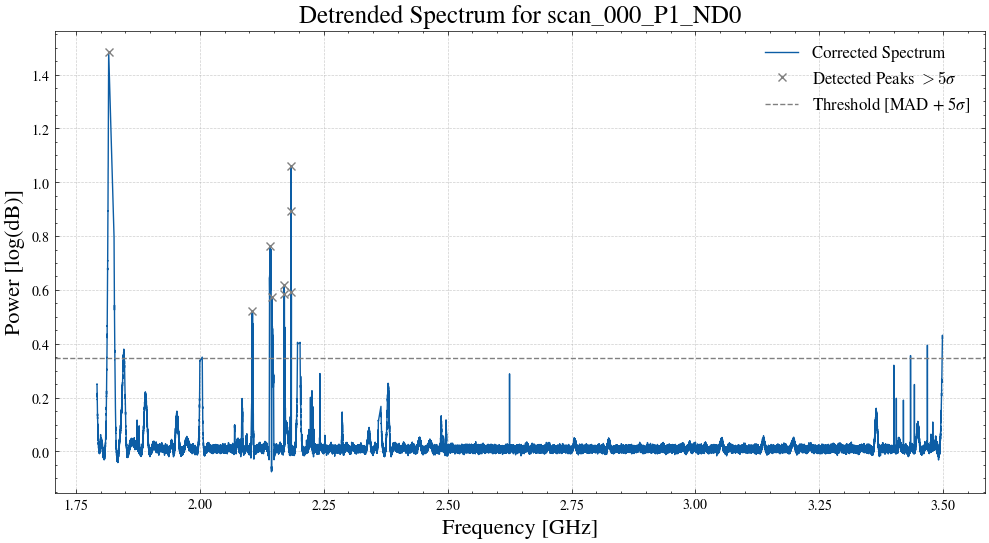

In [14]:
# Detrend the signal
detrended_spectrum_low = base_correction(mask_frequency_ghz, mask_signal_mean)

# Find peaks above 1 sigma from the MAD
sigma_value = 5
peaks_low, propreties = find_peaks(detrended_spectrum_low, 
                            height=MAD(detrended_spectrum_low) + sigma_value*np.std(detrended_spectrum_low),
                            distance=10,
                            prominence=0.5
                            )
plt.figure(figsize=(12,6))
plt.plot(mask_frequency_ghz, detrended_spectrum_low, label='Corrected Spectrum')
plt.plot(mask_frequency_ghz[peaks_low],  detrended_spectrum_low[peaks_low], 'x', color='gray', label=f'Detected Peaks $>{sigma_value}σ$')
plt.axhline(y=MAD(detrended_spectrum_low) + sigma_value*np.std(detrended_spectrum_low), 
                color='gray', linestyle='--', label=f'Threshold [MAD + {sigma_value}$σ$]')
plt.xlabel("Frequency [GHz]", fontsize=16)
plt.ylabel("Power [log(dB)]", fontsize=16)
plt.title(f"Detrended Spectrum for {scan_name}", fontsize=18)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=12)

  # --- Print detected peak frequencies ---
peak_freqs_low = [f"{f:.4f}" for f in mask_frequency_ghz[peaks_low]]
print(f"Detected peak > {sigma_value}σ are frequencies (GHz): {peak_freqs_low}")

# Peform the VM2R for the high level and low level peaks


In [15]:
spectrum_db.shape

(634, 63877)

In [16]:
results_high = variance_to_median_square_ratio_single_dish(xr.DataArray(spectrum, dims=['time', 'frequency']), time_dim='time', freq_dim='frequency')

results_low = variance_to_median_square_ratio_single_dish(xr.DataArray(mask_signal, dims=['time', 'mask_frequency_ghz']), time_dim='time', freq_dim='mask_frequency_ghz')


In [17]:
results_high

<xarray.Dataset> Size: 2MB
Dimensions:       (frequency: 63877)
Dimensions without coordinates: frequency
Data variables:
    median        (frequency) float64 511kB dask.array<chunksize=(63877,), meta=np.ndarray>
    variance      (frequency) float64 511kB dask.array<chunksize=(63877,), meta=np.ndarray>
    vm2r          (frequency) float64 511kB dask.array<chunksize=(63877,), meta=np.ndarray>
    vm2r_by_freq  (frequency) float64 511kB dask.array<chunksize=(63877,), meta=np.ndarray>
    vm2r_global   float64 8B 0.3376

In [18]:
vm2r_high = results_high['vm2r_by_freq']
vm2r_low = results_low['vm2r_by_freq']

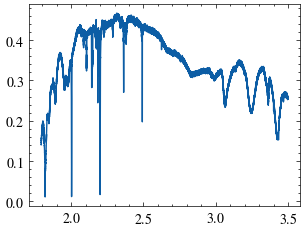

In [19]:
plt.plot(frequency, vm2r_high, label="VM2R for masked signal")

In [20]:
np.max(vm2r_low.compute().values)

np.float64(0.0001990361182280895)

In [21]:
frequency[flag]

array([1.8162899 , 1.8163166 , 1.81634331, ..., 2.49264717, 2.49267387,
       2.49270058], shape=(1023,))

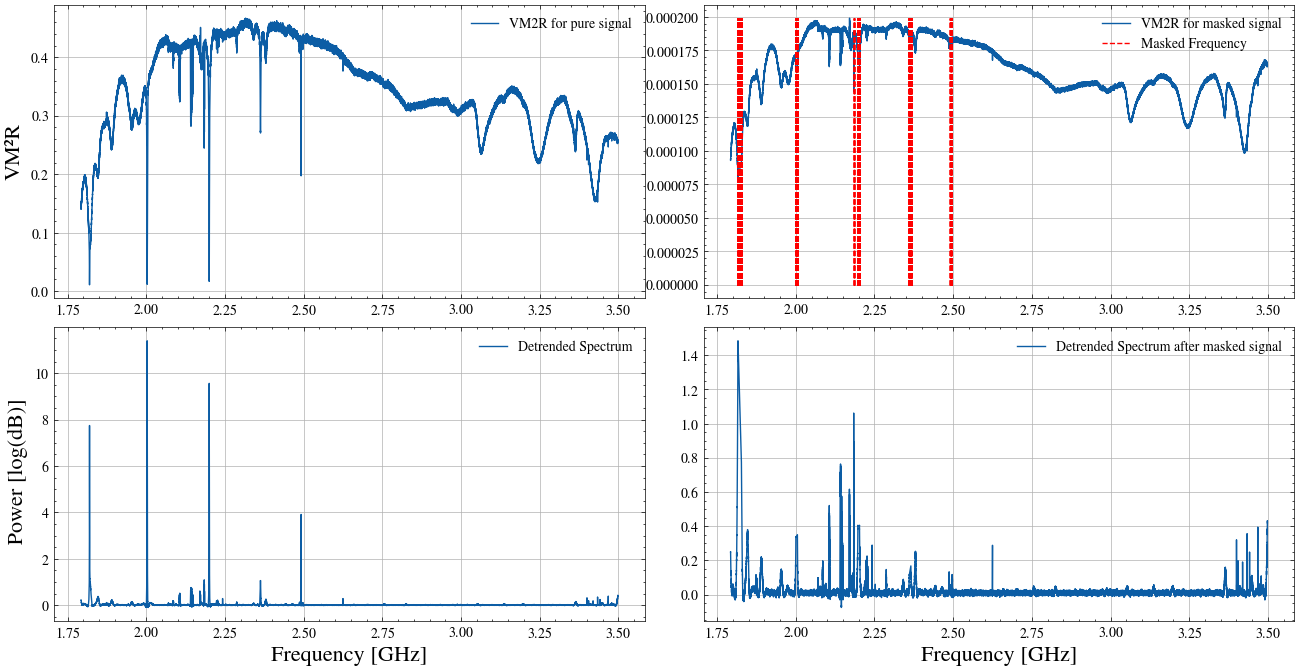

In [22]:
fig, ax = plt.subplots(2,2,figsize=(16, 8))
fig.subplots_adjust(wspace=0.1, hspace=0.1)

ax[0,0].plot(frequency, vm2r_high, label="VM2R for pure signal")
#ax[0,0].set_xlabel("Frequency [GHz]",fontsize=16)
ax[0,0].set_ylabel("VM²R",fontsize=16)
ax[0,0].grid()
ax[0,0].legend()

ax[1,0].plot(frequency, detrended_spectrum, label="Detrended Spectrum")
ax[1,0].set_xlabel("Frequency [GHz]",fontsize=16)
ax[1,0].set_ylabel(" Power [log(dB)]",fontsize=16)
ax[1,0].grid()
ax[1,0].legend()


ax[0,1].plot(mask_frequency_ghz, vm2r_low, label="VM2R for masked signal")
ax[0,1].vlines(frequency[flag], ymin=0, ymax=np.max(vm2r_low.compute().values), color='red', linestyle='--', label='Masked Frequency')
#ax[0,1].set_xlabel("Frequency [GHz]",fontsize=16)
#ax[0,1].set_ylabel("VM²R",fontsize=16)
ax[0,1].grid()
ax[0,1].legend()

ax[1,1].plot(mask_frequency_ghz, detrended_spectrum_low, label="Detrended Spectrum after masked signal")
ax[1,1].set_xlabel("Frequency [GHz]",fontsize=16)
#ax[1,1].set_ylabel("Average Power [log(dB)]",fontsize=16)
ax[1,1].grid()
ax[1,1].legend()

VM²R Comparison for scan_000_P1_ND0


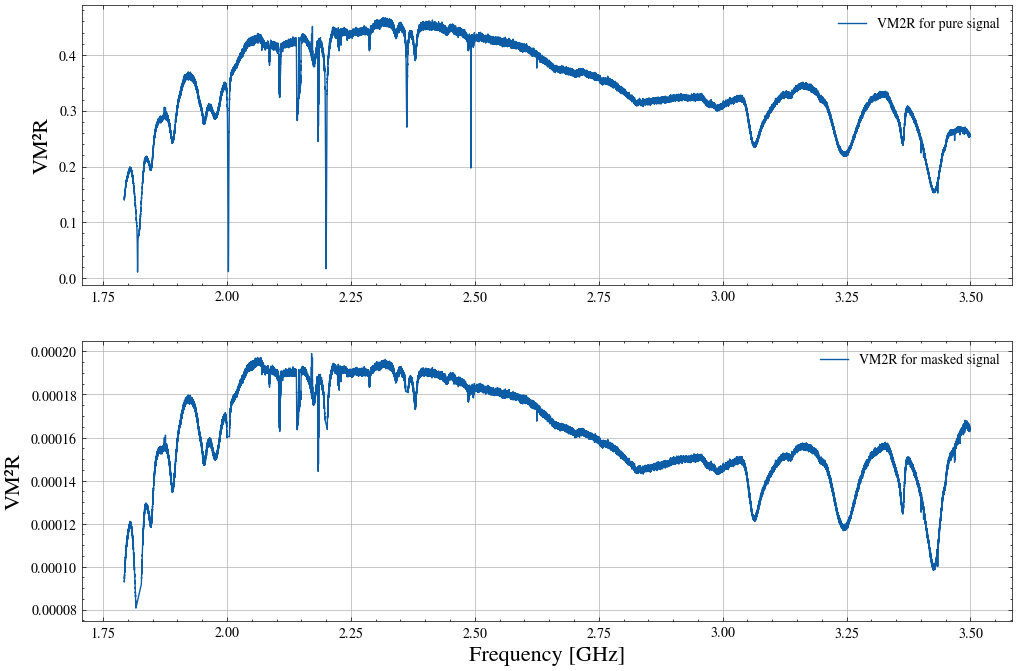

In [23]:
print(f"VM²R Comparison for {scan_name}")

fig, ax = plt.subplots(2,1,figsize=(12, 8))
fig.subplots_adjust(hspace=0.2)

ax[0].plot(frequency, vm2r_high, label="VM2R for pure signal")
#ax[0].set_xlabel("Frequency [GHz]",fontsize=16)
ax[0].set_ylabel("VM²R",fontsize=16)
ax[0].grid()
ax[0].legend()

ax[1].plot(mask_frequency_ghz, vm2r_low, label="VM2R for masked signal")
ax[1].set_xlabel("Frequency [GHz]",fontsize=16)
ax[1].set_ylabel("VM²R",fontsize=16)
ax[1].grid()
ax[1].legend()


if to_save:
    # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    plot_png = os.path.join(full_path, f'VM2R{scan_name}.png')
    plot_pdf = os.path.join(full_path, f'VM2R{scan_name}.pdf')
    plt.savefig(plot_png, dpi=300, bbox_inches='tight')
    plt.savefig(plot_pdf, dpi=300, bbox_inches='tight')

[]

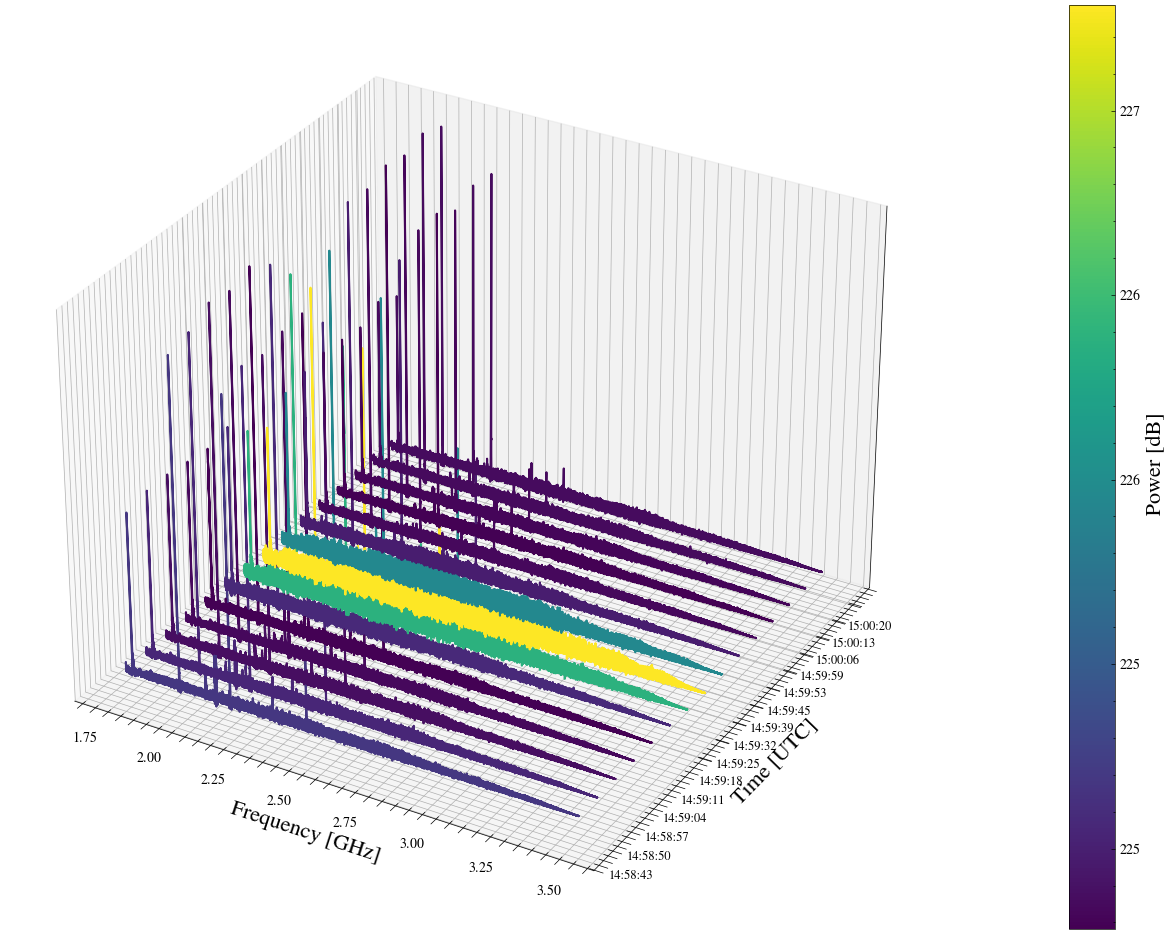

In [24]:


n_time, n_freq = spectrum.shape

# --- Configuration ---
n_samples = 15
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

# --- Convert Time to UTC Datetime ---
time_utc = pd.to_datetime(time, unit="s", utc=True)

# --- Convert time to numeric seconds (for 3D axis) ---
time_seconds = np.array(
    [(t - time_utc[0]).total_seconds() for t in time_utc]
)

# --- Compute detrended power + corrected spectra ---
det_power = np.zeros(n_time)
corrected_spectra = []
selected_times = []
# 1. Calculate scalar power for each selected index
det_power_list = []
for k in idx:
    spectra = spectrum[k, :]
    corrected = base_correction(frequency, spectra)
    corrected_spectra.append(corrected)
    
    # Calculate scalar power in dB
    pwr = 10 * np.log10(np.nanmean(corrected**2))
    det_power_list.append(pwr)
    selected_times.append(time_seconds[k])

det_power_array = np.array(det_power_list)

# 2. Setup Color Mapping
norm = plt.Normalize(vmin=det_power_array.min(), vmax=det_power_array.max())
# Map the scalar power values to colors
colors = cm.viridis(norm(det_power_array)) 

# 3. Plotting
fig = plt.figure(figsize=(18, 12))
ax = fig.add_subplot(111, projection='3d')

for y_spec, t_sec, color in zip(corrected_spectra, selected_times, colors):
    # Normalize Z-axis for visual consistency (ridges)
    y_norm = (y_spec - np.nanmean(y_spec)) / np.nanstd(y_spec)
    
    time_array = np.full_like(frequency, t_sec)
    
    # Plot the line with the color corresponding to its power level
    ax.plot(frequency, time_array, y_norm, color=color, lw=1.5)



# --- Colorbar ---
sm = cm.ScalarMappable(cmap=cm.viridis, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1)
cbar.set_label(" Power [dB]", fontsize=16)
cbar.ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%d'))

# --- Y-axis sampled UTC labels ---
tick_indices = idx
tick_positions = time_seconds[tick_indices]
tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_indices]

ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=9)

# --- Labels ---
ax.set_xlabel("Frequency [GHz]", fontsize=16)
ax.set_ylabel("Time [UTC]", fontsize=16)
ax.set_zticks([])

In [25]:
det_power_array

array([225.18130561, 225.04876126, 224.87989051, 224.83328497,
       224.78417742, 225.07071934, 226.3784932 , 227.28594856,
       225.94679423, 224.98134105, 224.83328841, 224.78229383,
       224.8145033 , 224.8497465 , 224.85572289])

In [26]:
results_high

<xarray.Dataset> Size: 2MB
Dimensions:       (frequency: 63877)
Dimensions without coordinates: frequency
Data variables:
    median        (frequency) float64 511kB dask.array<chunksize=(63877,), meta=np.ndarray>
    variance      (frequency) float64 511kB dask.array<chunksize=(63877,), meta=np.ndarray>
    vm2r          (frequency) float64 511kB dask.array<chunksize=(63877,), meta=np.ndarray>
    vm2r_by_freq  (frequency) float64 511kB dask.array<chunksize=(63877,), meta=np.ndarray>
    vm2r_global   float64 8B 0.3376

In [27]:
vm2r_list = []

window = 50

for k in idx:

    # Avoid overflow at the end
    if k + window > n_time:
        continue

    spectra_block = spectrum_db[k:k+window, :]

    da = xr.DataArray(
        spectra_block,
        dims=['time', 'frequency'],
        coords={
            'time': np.arange(window),
            'frequency': frequency
        }
    )

    vm2r_results = variance_to_median_square_ratio_single_dish(
        da,
        time_dim='time',
        freq_dim='frequency'
    )

    vm2r_freq = vm2r_results['vm2r_by_freq'].values

    vm2r_list.append(vm2r_freq)

#convert list to array
vm2r_array = np.array(vm2r_list)

In [28]:
vm2r_array.shape

(13, 63877)

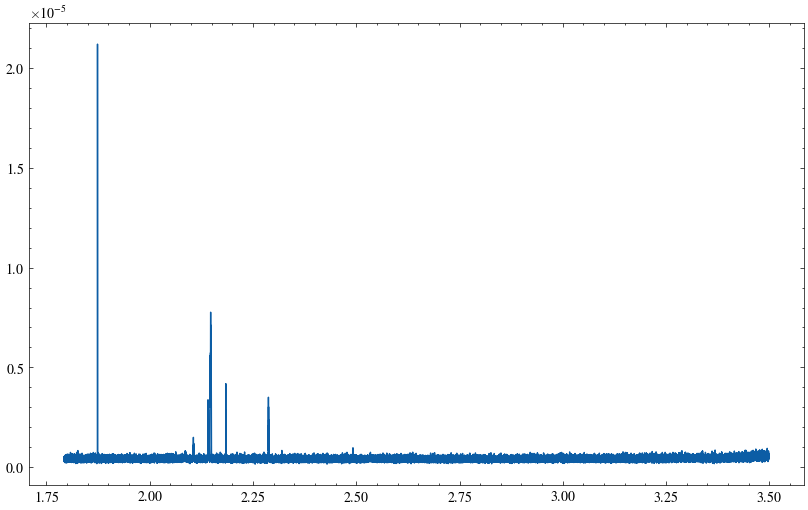

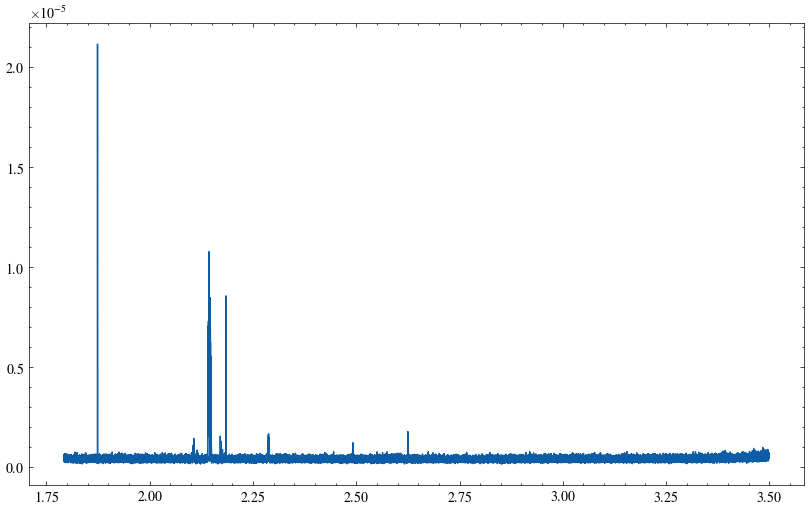

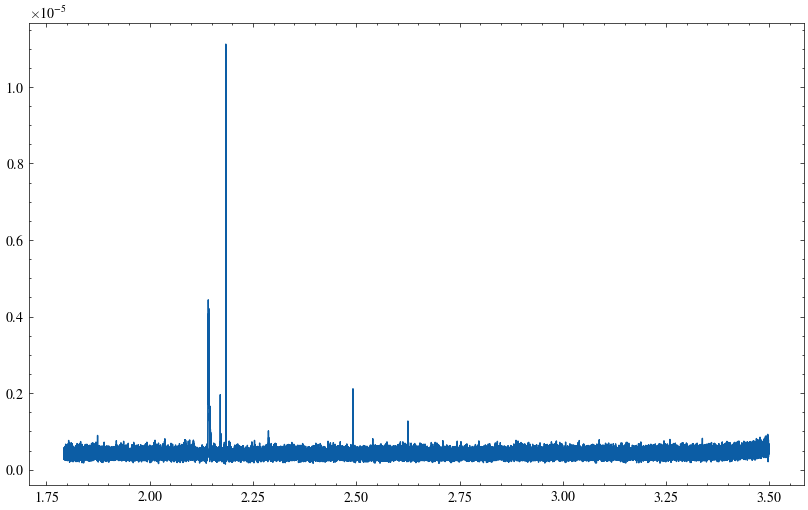

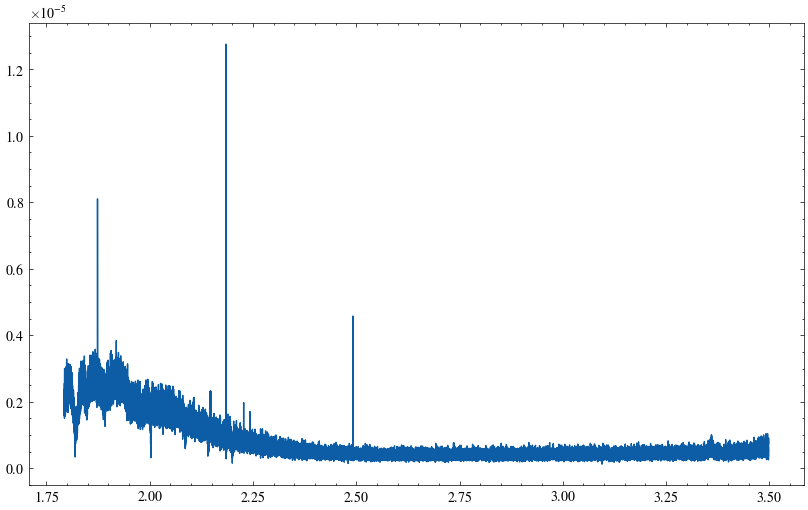

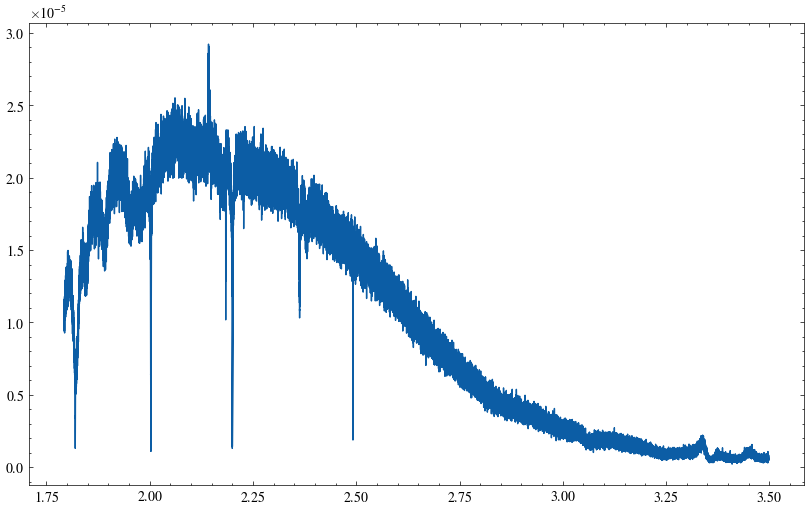

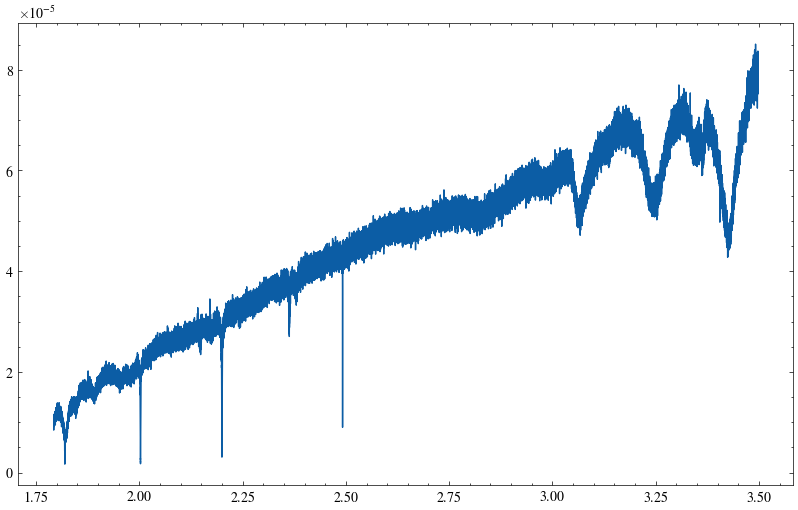

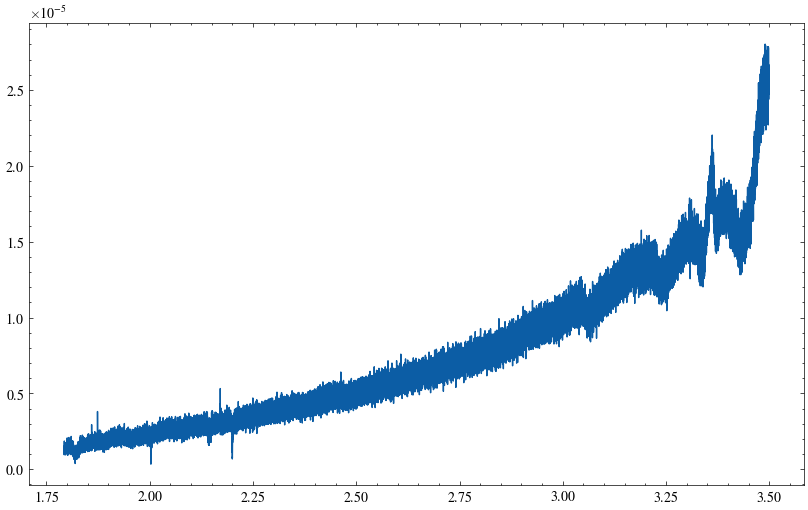

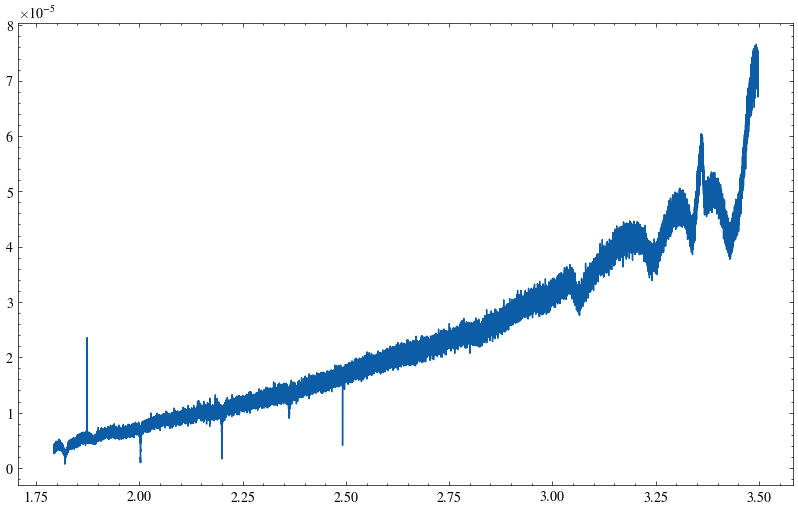

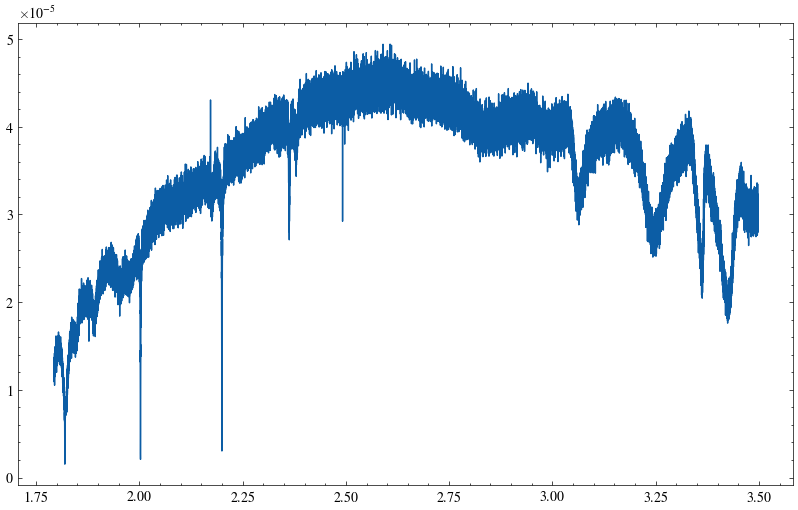

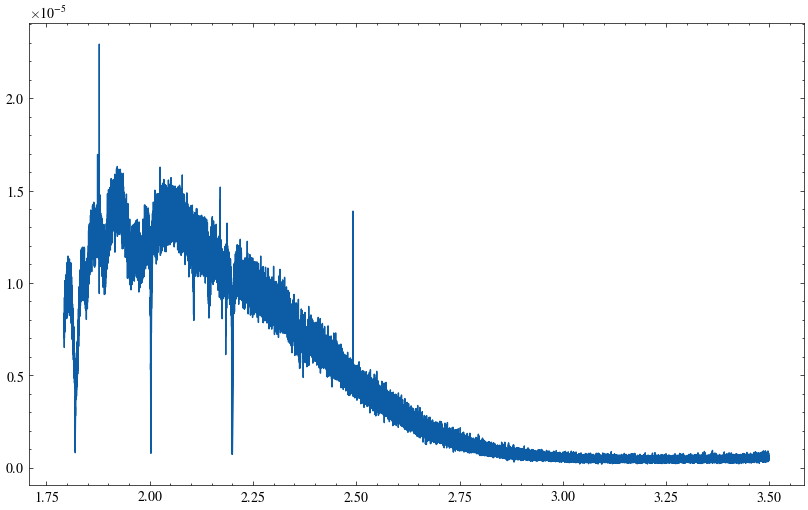

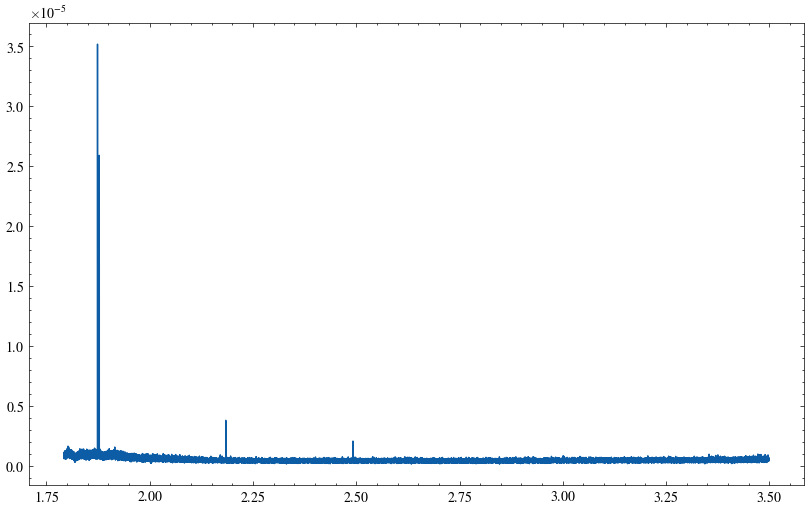

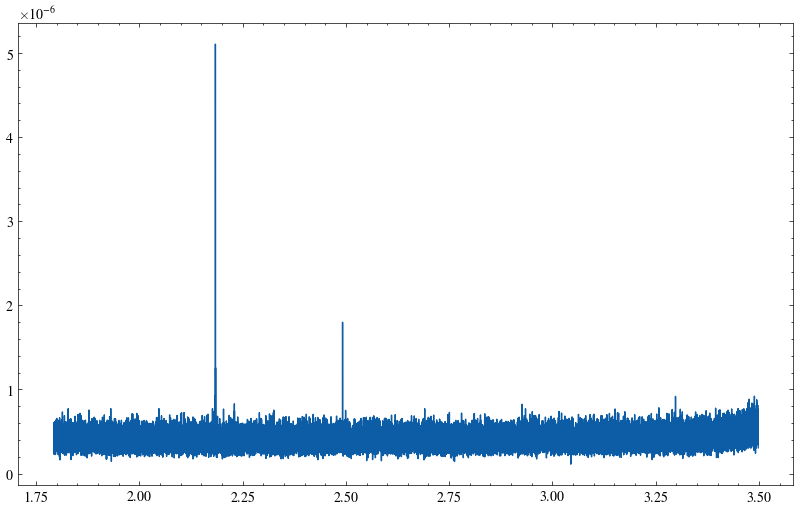

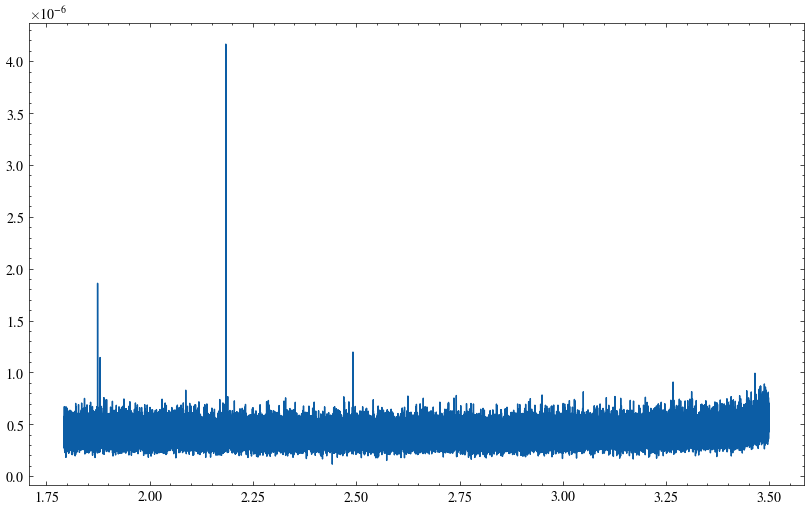

In [29]:

for i in range(vm2r_array.shape[0]):
    plt.figure(figsize=(10, 6))

    plt.plot(frequency, vm2r_array[i])
    

[]

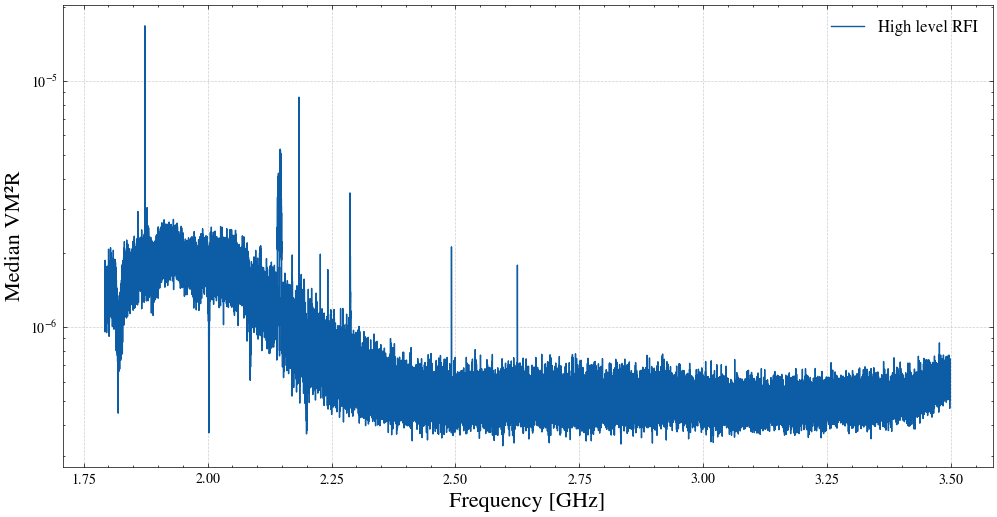

In [30]:
vm2r_median = np.median(vm2r_array, axis=0)

plt.figure(figsize=(12, 6))
plt.plot(frequency, vm2r_median, label='High level RFI')
plt.xlabel("Frequency [GHz]", fontsize=16)
plt.ylabel("Median VM²R", fontsize=16)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=12) 
#plt.title(f"Median VM²R high level RFI {scan_name}", fontsize=18)
plt.semilogy()

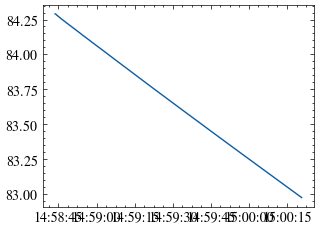

In [31]:
plt.plot(time_utc, ra[2:])

In [32]:
results_freq = variance_to_median_square_ratio_time(xr.DataArray(spectrum, dims=['time', 'frequency']), time_dim='time', freq_dim='frequency')
results_freq

<xarray.Dataset> Size: 20kB
Dimensions:       (time: 634)
Dimensions without coordinates: time
Data variables:
    median        (time) float64 5kB dask.array<chunksize=(634,), meta=np.ndarray>
    variance      (time) float64 5kB dask.array<chunksize=(634,), meta=np.ndarray>
    vm2r          (time) float64 5kB dask.array<chunksize=(634,), meta=np.ndarray>
    vm2r_by_time  (time) float64 5kB dask.array<chunksize=(634,), meta=np.ndarray>
    vm2r_global   float64 8B 0.1376

Text(0.5, 0, 'Time [s]')

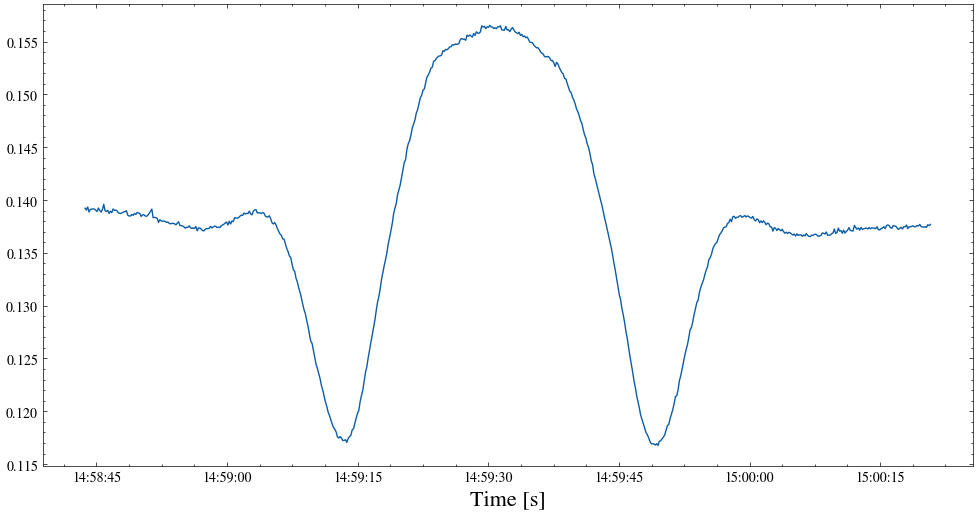

In [33]:
vm2r_freq = results_freq['vm2r_by_time'].values
plt.figure(figsize=(12, 6))
plt.plot(time_utc, vm2r_freq, label='VM²R by Time')
#plt.plot(vm2r_freq[0:150])
plt.xlabel("Time [s]", fontsize=16)

In [34]:
import numpy as np
import astropy.units as u

from astropy.coordinates import (
    SkyCoord,
    AltAz,
    EarthLocation,
)
from astropy.time import Time


In [35]:


def compute_pointing_offset(
    azimuth,
    elevation,
    target_ra,
    target_dec,
    obstime,
    latitude,
    longitude,
    height=0.0,
    az_unit=u.deg,
    el_unit=u.deg,
    ra_unit=u.deg,
    dec_unit=u.deg,
):
    """
    Compute the angular separation between the telescope pointing
    direction (Az/El) and a target sky position (RA/Dec).

    Parameters
    ----------
    azimuth : float or array-like
        Telescope azimuth coordinates.

    elevation : float or array-like
        Telescope elevation (altitude) coordinates.

    target_ra : float
        Right Ascension of the target source.

    target_dec : float
        Declination of the target source.

    obstime : str, astropy.time.Time, or array-like
        Observation time(s). Can be:
            - ISO string
            - Astropy Time object
            - list/array of times

    latitude : float
        Observatory latitude.

    longitude : float
        Observatory longitude.

    height : float, optional
        Observatory height above sea level in meters.
        Default is 0.

    az_unit : astropy.units.Unit
        Unit of azimuth values.
        Default is degrees.

    el_unit : astropy.units.Unit
        Unit of elevation values.
        Default is degrees.

    ra_unit : astropy.units.Unit
        Unit of Right Ascension.
        Default is degrees.

    dec_unit : astropy.units.Unit
        Unit of Declination.
        Default is degrees.

    Returns
    -------
    separation : astropy.coordinates.Angle
        Angular separation between telescope pointing and target.

    separation_deg : ndarray
        Angular separation in degrees.

    Notes
    -----
    This function works by:

    1. Defining the observatory location.
    2. Constructing the telescope pointing direction in the AltAz frame.
    3. Constructing the target source in the ICRS frame.
    4. Transforming the target into the local AltAz frame.
    5. Computing the great-circle angular separation.

    The angular separation is given by:

    """

        # ------------------------------------------------------------------
    # Observatory location
    # ------------------------------------------------------------------
    location = EarthLocation(
        lat=latitude * u.deg,
        lon=longitude * u.deg,
        height=height * u.m,
    )

    # ------------------------------------------------------------------
    # Observation time
    # ------------------------------------------------------------------
    obstime = Time(obstime)

    # ------------------------------------------------------------------
    # Telescope pointing coordinates (AltAz frame)
    # ------------------------------------------------------------------
    telescope_pointing = SkyCoord(
        az=np.asarray(azimuth) * az_unit,
        alt=np.asarray(elevation) * el_unit,
        frame=AltAz(
            obstime=obstime,
            location=location,
        ),
    )

    # ------------------------------------------------------------------
    # Target source coordinates (ICRS frame)
    # ------------------------------------------------------------------
    target_icrs = SkyCoord(
        ra=target_ra * ra_unit,
        dec=target_dec * dec_unit,
        frame="icrs",
    )

    # ------------------------------------------------------------------
    # Transform target to local AltAz frame
    # ------------------------------------------------------------------
    target_altaz = target_icrs.transform_to(
        AltAz(
            obstime=obstime,
            location=location,
        )
    )

    # ------------------------------------------------------------------
    # Angular separation
    # ------------------------------------------------------------------
    separation = telescope_pointing.separation(target_altaz)

    return separation, separation.deg

In [36]:
# Example:
sep_angle, sep_deg = compute_pointing_offset(
    azimuth=180.0,
    elevation=45.0,
    target_ra=83.6331,      # Crab Nebula RA
    target_dec=22.0145,     # Crab Nebula DEC
    obstime="2026-04-18T12:00:00",
    latitude=-30.7215,      # MeerKAT latitude
    longitude=21.4110,      # MeerKAT longitude
    height=1050,            # meters
)

print(sep_angle)
print(sep_deg)

100d17m12.50255647s
100.28680626568611


In [37]:
# # Example:

# for time, i in enumerate(time_utc):
#      sep_angle, sep_deg = compute_pointing_offset(
#         azimuth=azimuth[i],
#         elevation=elevation[i],
#         target_ra=ra[i],      # Crab Nebula RA
#         target_dec=dec[i],     # Crab Nebula DEC
#         obstime=time,
#         latitude=-30.7215,      # MeerKAT latitude
#         longitude=21.4110,      # MeerKAT longitude
#         height=1050,            # meters
#     )

#      print(f"Time: {time_utc[i]}, Separation: {sep_angle}, Separation (deg): {sep_deg}")
# sep_angle, sep_deg = compute_pointing_offset(
#     azimuth=180.0,
#     elevation=45.0,
#     target_ra=83.6331,      # Crab Nebula RA
#     target_dec=22.0145,     # Crab Nebula DEC
#     obstime="2026-04-18T12:00:00",
#     latitude=-30.7215,      # MeerKAT latitude
#     longitude=21.4110,      # MeerKAT longitude
#     height=1050,            # meters
# )

# print(sep_angle)
# print(sep_deg)

In [38]:
ra_taurus = 83.6331
dec_taurus = +22.0145

In [39]:
angular_separation = []

for i in range(len(time_utc)):
    
    # ------------------------------------------------------------------
    # Telescope pointing coordinates (AltAz frame)
    # ------------------------------------------------------------------
    telescope_pointing = SkyCoord(
        ra=ra[i] * u.deg,
        dec=dec[i] * u.deg,
        frame="icrs",
    )

    # ------------------------------------------------------------------
    # Target source coordinates (ICRS frame)
    # ------------------------------------------------------------------
    target_icrs = SkyCoord(
        ra=ra_taurus * u.deg,
        dec=dec_taurus * u.deg,
        frame="icrs",
    )


    # ------------------------------------------------------------------
    # Angular separation
    # ------------------------------------------------------------------
    separation = telescope_pointing.separation(target_icrs)
    angular_separation.append(separation.value)

In [40]:
angular_separation

[np.float64(1.5856333209490416),
 np.float64(1.586629096296113),
 np.float64(1.5836301475067633),
 np.float64(1.5848052848159344),
 np.float64(1.5832450385830816),
 np.float64(1.57440419307811),
 np.float64(1.5680321688484682),
 np.float64(1.5666577471728285),
 np.float64(1.5604804777898773),
 np.float64(1.5518215813298528),
 np.float64(1.5483159784573495),
 np.float64(1.54534255686136),
 np.float64(1.5372996424812433),
 np.float64(1.5307689515411895),
 np.float64(1.5283047926786135),
 np.float64(1.5231532427165486),
 np.float64(1.515204409605088),
 np.float64(1.5109392118884688),
 np.float64(1.5076709687170824),
 np.float64(1.5008838207453767),
 np.float64(1.4944756741369123),
 np.float64(1.4911186407233088),
 np.float64(1.4863628421071027),
 np.float64(1.4791574458776056),
 np.float64(1.4741402916870714),
 np.float64(1.4707022963469167),
 np.float64(1.464748114689633),
 np.float64(1.458164026610831),
 np.float64(1.4544194092251423),
 np.float64(1.4502005056687122),
 np.float64(1.4433

Text(0.5, 1.0, 'Angular Separation between Telescope Pointing and Taurus A')

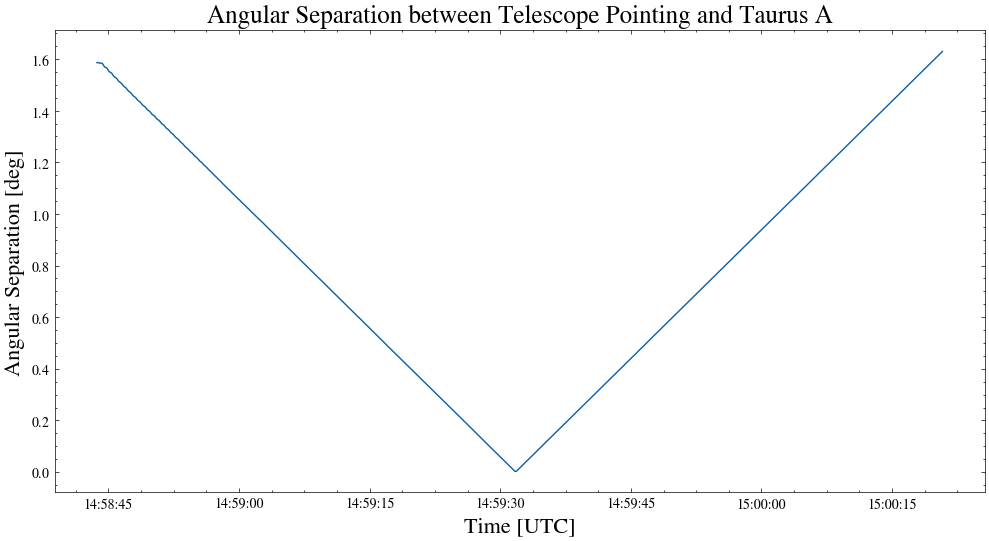

In [41]:
plt.figure(figsize=(12, 6))
plt.plot(time_utc, angular_separation)
plt.xlabel("Time [UTC]", fontsize=16)
plt.ylabel("Angular Separation [deg]", fontsize=16)
plt.title("Angular Separation between Telescope Pointing and Taurus A", fontsize=18)

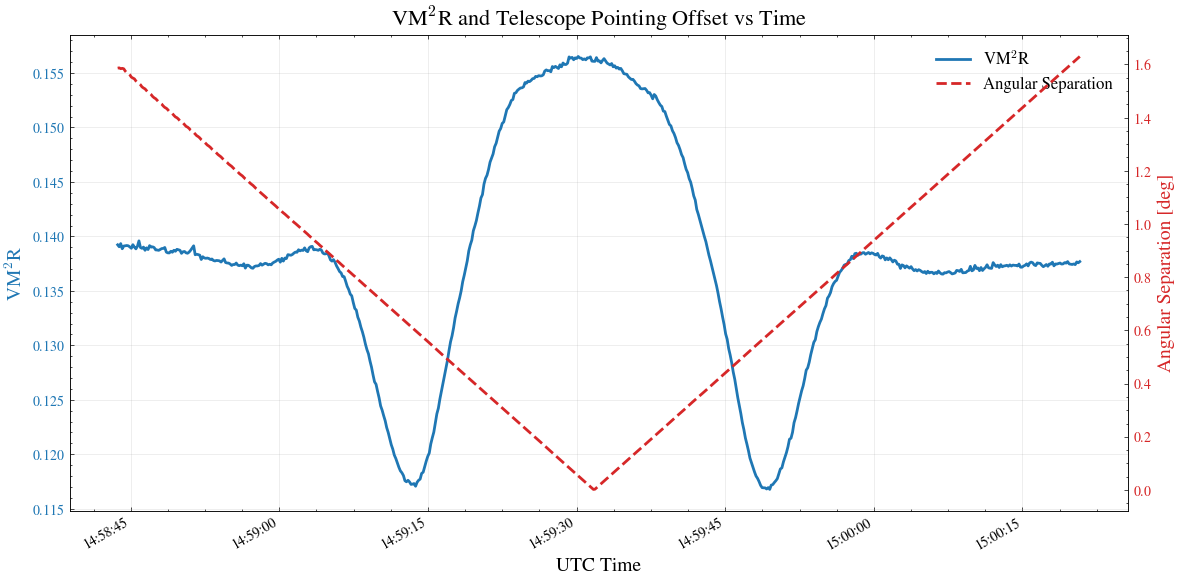

In [42]:

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(12, 6))

# ------------------------------------------------------------
# Left axis : VM²R
# ------------------------------------------------------------
line1 = ax1.plot(
    time_utc,
    vm2r_freq,
    color='tab:blue',
    linewidth=2,
    label='VM$^2$R'
)

ax1.set_xlabel("UTC Time", fontsize=14)

ax1.set_ylabel(
    "VM$^2$R",
    color='tab:blue',
    fontsize=14
)

ax1.tick_params(
    axis='y',
    labelcolor='tab:blue'
)

# ------------------------------------------------------------
# Right axis : Angular separation
# ------------------------------------------------------------
ax2 = ax1.twinx()

line2 = ax2.plot(
    time_utc,
    angular_separation,
    color='tab:red',
    linewidth=2,
    linestyle='--',
    label='Angular Separation'
)

ax2.set_ylabel(
    "Angular Separation [deg]",
    color='tab:red',
    fontsize=14
)

ax2.tick_params(
    axis='y',
    labelcolor='tab:red'
)

# ------------------------------------------------------------
# Time formatting
# ------------------------------------------------------------
ax1.xaxis.set_major_formatter(
    mdates.DateFormatter('%H:%M:%S')
)

fig.autofmt_xdate()

# ------------------------------------------------------------
# Combined legend
# ------------------------------------------------------------
lines = line1 + line2
labels = [l.get_label() for l in lines]

ax1.legend(
    lines,
    labels,
    loc='upper right',
    fontsize=12
)

# ------------------------------------------------------------
# Grid and layout
# ------------------------------------------------------------
ax1.grid(True, alpha=0.3)

plt.title(
    "VM$^2$R and Telescope Pointing Offset vs Time",
    fontsize=16
)

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Mean Spectrum [dB]')

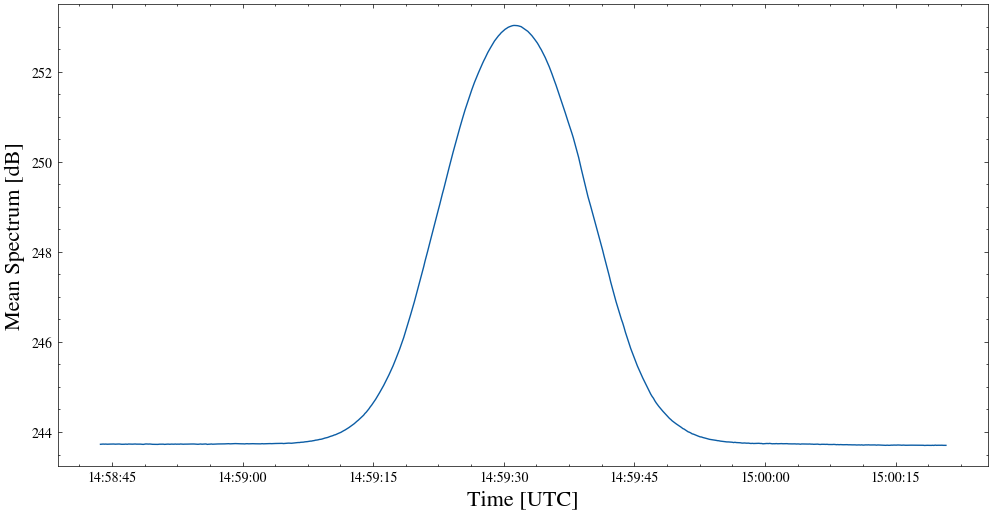

In [43]:
spectrum_db_fre = np.mean(spectrum_db, axis=1)


plt.figure(figsize=(12, 6))
plt.plot(time_utc, spectrum_db_fre)
plt.xlabel("Time [UTC]", fontsize=16)
plt.ylabel("Mean Spectrum [dB]", fontsize=16)

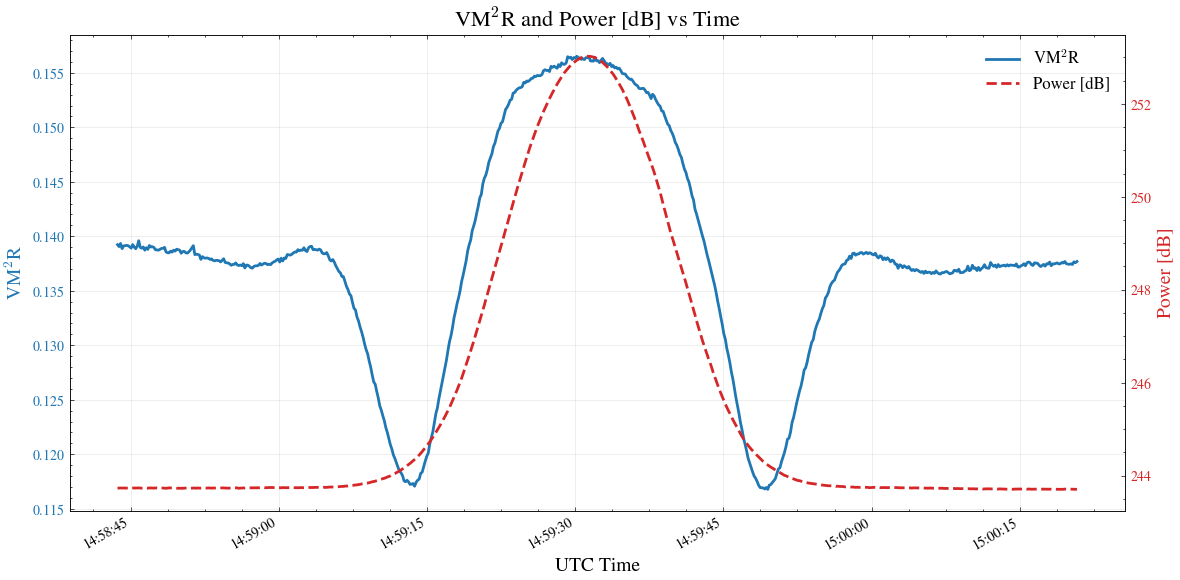

In [44]:


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(12, 6))

# ------------------------------------------------------------
# Left axis : VM²R
# ------------------------------------------------------------
line1 = ax1.plot(
    time_utc,
    vm2r_freq,
    color='tab:blue',
    linewidth=2,
    label='VM$^2$R'
)

ax1.set_xlabel("UTC Time", fontsize=14)

ax1.set_ylabel(
    "VM$^2$R",
    color='tab:blue',
    fontsize=14
)

ax1.tick_params(
    axis='y',
    labelcolor='tab:blue'
)

# ------------------------------------------------------------
# Right axis : Angular separation
# ------------------------------------------------------------
ax2 = ax1.twinx()

line2 = ax2.plot(
    time_utc,
    spectrum_db_fre,
    color='tab:red',
    linewidth=2,
    linestyle='--',
    label='Power [dB]'
)

ax2.set_ylabel(
    "Power [dB]",
    color='tab:red',
    fontsize=14
)

ax2.tick_params(
    axis='y',
    labelcolor='tab:red'
)

# ------------------------------------------------------------
# Time formatting
# ------------------------------------------------------------
ax1.xaxis.set_major_formatter(
    mdates.DateFormatter('%H:%M:%S')
)

fig.autofmt_xdate()

# ------------------------------------------------------------
# Combined legend
# ------------------------------------------------------------
lines = line1 + line2
labels = [l.get_label() for l in lines]

ax1.legend(
    lines,
    labels,
    loc='upper right',
    fontsize=12
)

# ------------------------------------------------------------
# Grid and layout
# ------------------------------------------------------------
ax1.grid(True, alpha=0.3)

plt.title(
    "VM$^2$R and Power [dB] vs Time",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [45]:
vm2r_freq.shape, len(angular_separation)

((634,), 634)

# VM2R by angular separation
#### Study how the spectral variability (VM²R) changes as a function of the telescope pointing offset from the source.

You already have:

* time_utc
* angular_separation(t)
* vm2r(t)

Now instead of plotting VM²R vs time, you want:

VM2R(θ)

where:

θ = angular separation.

But because:

* many time samples can fall into similar angular separations,
* the data may be noisy,

you should bin the angular separation.

In [46]:

from scipy.stats import binned_statistic


In [49]:
angular_separation_array = np.array(angular_separation)

In [50]:
angular_separation_array.min(), angular_separation_array.max()

(np.float64(0.002355015608848644), np.float64(1.6294167613545776))

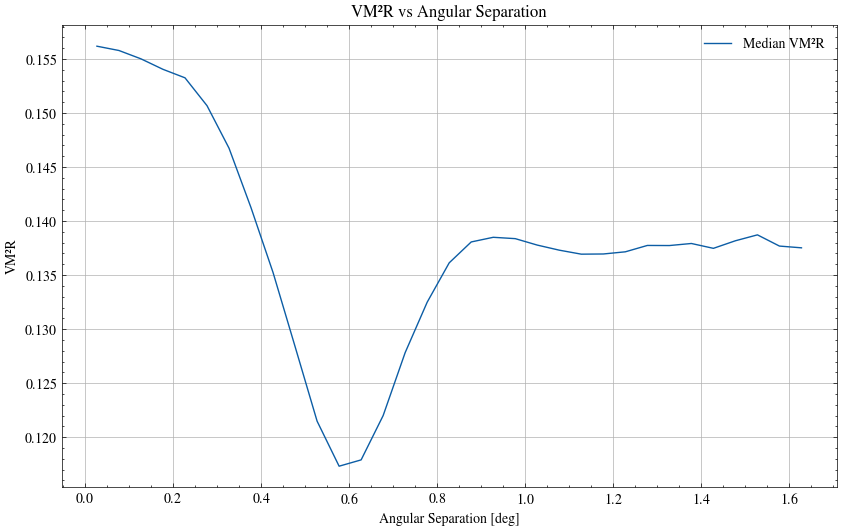

In [54]:

bin_width = 0.05  # degrees

bins = np.arange(
    angular_separation_array.min(),
    angular_separation_array.max() + bin_width,
    bin_width
)

# ----------------------------------------------------------
# Compute statistics per bin
# ----------------------------------------------------------

# Median VM2R in each angular bin
vm2r_median, bin_edges, _ = binned_statistic(
    angular_separation_array,
    vm2r_freq,
    statistic='median',
    bins=bins
)

# Mean VM2R
vm2r_mean, _, _ = binned_statistic(
    angular_separation_array,
    vm2r_freq,
    statistic='mean',
    bins=bins
)

# Standard deviation
vm2r_std, _, _ = binned_statistic(
    angular_separation_array,
    vm2r_freq,
    statistic='std',
    bins=bins
)

# Bin centers
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# ----------------------------------------------------------
# Plot
# ----------------------------------------------------------
plt.figure(figsize=(10,6))

plt.plot(
    bin_centers,
    vm2r_median,
    label='Median VM²R'
)

# plt.fill_between(
#     bin_centers,
#     vm2r_median - vm2r_std,
#     vm2r_median + vm2r_std,
#     alpha=0.3,
#     label='±1σ'
# )

plt.xlabel("Angular Separation [deg]")
plt.ylabel("VM²R")
plt.title("VM²R vs Angular Separation")

plt.grid(True)
plt.legend()

plt.show()

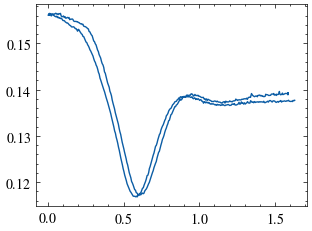

In [55]:
plt.plot(angular_separation_array, vm2r_freq)